<a href="https://www.kaggle.com/code/tanviatimb/avalia-o-final-t-cnicas-de-ia?scriptVersionId=371675214" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# 1. Criando os dados

In [2]:
# Importar as bibliotecas
import numpy as np
import matplotlib.pyplot as plt

def gerar_espirais(n_por_classe=200, ruido=0.2, seed=42):
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []

    for classe in (0, 1):
        # Angulo e raio para formar espirais entrelaçadas
        theta = np.linspace(0, 3 * np.pi, n_por_classe) + classe * np.pi
        r = np.linspace(0.1, 1.0, n_por_classe)

        x1 = r * np.cos(theta) + rng.normal(0, ruido * 0.15, n_por_classe)
        x2 = r * np.sin(theta) + rng.normal(0, ruido * 0.15, n_por_classe)

        X_list.append(np.column_stack([x1, x2]))
        y_list.append(np.full(n_por_classe, classe, dtype=np.float64))

    X = np.vstack(X_list)
    y = np.concatenate(y_list).reshape(-1, 1)

    # Embaralha os dados
    indices = rng.permutation(len(X))
    return X[indices], y[indices]


# 400 pontos para treino (200 por classe) e 400 pontos inéditos para teste
X_train, y_train = gerar_espirais(n_por_classe=200, ruido=0.2, seed=42)
X_test, y_test = gerar_espirais(n_por_classe=200, ruido=0.2, seed=123)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")

X_train: (400, 2), y_train: (400, 1)
X_test:  (400, 2),  y_test:  (400, 1)


# 2. Inicializando parâmetros (2 -> 32 -> 32 -> 1 = 1.185)

In [3]:
def inicializar_rede(d_in=2, h1_dim=32, h2_dim=32, d_out=1, seed=42):
    rng = np.random.default_rng(seed)
    scale = 0.5

    params = {
        "W1": rng.normal(0, scale, (d_in, h1_dim)),
        "b1": np.zeros((1, h1_dim)),
        "W2": rng.normal(0, scale, (h1_dim, h2_dim)),
        "b2": np.zeros((1, h2_dim)),
        "W3": rng.normal(0, scale, (h2_dim, d_out)),
        "b3": np.zeros((1, d_out)),
    }
    total_params = sum(p.size for p in params.values())
    print(f"Total de parametros: {total_params}")
    return params


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def binary_cross_entropy(y_true, y_pred):
    eps = 1e-12
    p = np.clip(y_pred, eps, 1.0 - eps)
    return -np.mean(y_true * np.log(p) + (1.0 - y_true) * np.log(1.0 - p))


def acuracia(y_true, y_pred):
    preds = (y_pred >= 0.5).astype(np.float64)
    return np.mean(preds == y_true) * 100.0

# 3. Forward e Backward (Full-batch gradient descent)

In [4]:
def forward(X, params):
    h1 = np.tanh(X @ params["W1"] + params["b1"])
    h2 = np.tanh(h1 @ params["W2"] + params["b2"])
    y_hat = sigmoid(h2 @ params["W3"] + params["b3"])
    cache = (X, h1, h2, y_hat)
    return y_hat, cache


def backward_e_atualizar(cache, y, params, lr=0.5):
    X, h1, h2, y_hat = cache
    N = X.shape[0]

    # Derivada combinada de BCE + Sigmoid: (1/N) * (y_hat - y)
    delta3 = (y_hat - y) / N
    dW3 = h2.T @ delta3
    db3 = np.sum(delta3, axis=0, keepdims=True)

    # Camada oculta 2: derivada de tanh(z2) e (1 - h2^2)
    delta2 = (delta3 @ params["W3"].T) * (1.0 - h2 ** 2)
    dW2 = h1.T @ delta2
    db2 = np.sum(delta2, axis=0, keepdims=True)

    # Camada oculta 1: derivada de tanh(z1) e (1 - h1^2)
    delta1 = (delta2 @ params["W2"].T) * (1.0 - h1 ** 2)
    dW1 = X.T @ delta1
    db1 = np.sum(delta1, axis=0, keepdims=True)

    # Atualizacao dos pesos e vieses
    params["W3"] -= lr * dW3
    params["b3"] -= lr * db3
    params["W2"] -= lr * dW2
    params["b2"] -= lr * db2
    params["W1"] -= lr * dW1
    params["b1"] -= lr * db1


# 4. Treinamento

In [5]:
params = inicializar_rede(d_in=2, h1_dim=32, h2_dim=32, d_out=1, seed=42)
steps = 5000
lr = 0.5

historico_loss = []
historico_acc = []

for step in range(1, steps + 1):
    y_hat, cache = forward(X_train, params)
    loss = binary_cross_entropy(y_train, y_hat)
    acc = acuracia(y_train, y_hat)

    historico_loss.append(loss)
    historico_acc.append(acc)

    backward_e_atualizar(cache, y_train, params, lr=lr)

    if step in (1, 2, 100, 500, 947, 1000, 2000, 3151, 5000):
        print(f"Passo {step:4d} | Loss: {loss:.4f} | Acuracia Treino: {acc:.2f}%")

# Avaliacao final em 400 pontos ineditos
y_test_pred, _ = forward(X_test, params)
acc_test = acuracia(y_test, y_test_pred)
print(f"\nAcuracia final no conjunto de teste (400 pontos ineditos): {acc_test:.2f}%")

Total de parametros: 1185
Passo    1 | Loss: 0.7316 | Acuracia Treino: 54.50%
Passo    2 | Loss: 0.6595 | Acuracia Treino: 62.25%
Passo  100 | Loss: 0.6440 | Acuracia Treino: 59.50%
Passo  500 | Loss: 0.2533 | Acuracia Treino: 96.00%
Passo  947 | Loss: 0.0473 | Acuracia Treino: 99.25%
Passo 1000 | Loss: 0.0421 | Acuracia Treino: 99.50%
Passo 2000 | Loss: 0.0118 | Acuracia Treino: 99.75%
Passo 3151 | Loss: 0.0056 | Acuracia Treino: 100.00%
Passo 5000 | Loss: 0.0028 | Acuracia Treino: 100.00%

Acuracia final no conjunto de teste (400 pontos ineditos): 100.00%


# 5. Visualização (Dados e Fronteira de Decisão)

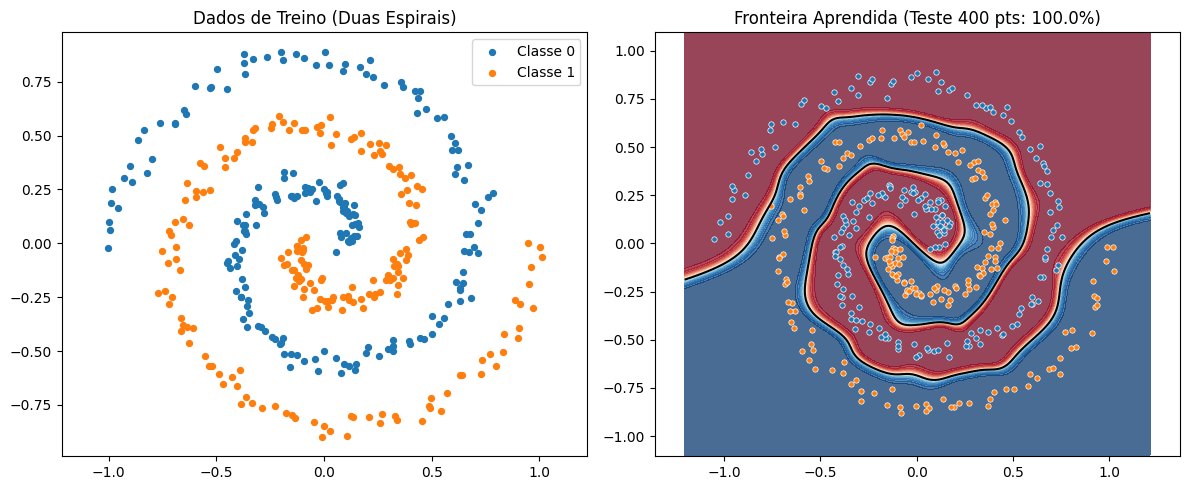

In [6]:
ig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Grafico 1: Dados de treino
axes[0].scatter(X_train[y_train[:, 0] == 0, 0], X_train[y_train[:, 0] == 0, 1],
                s=18, label="Classe 0")
axes[0].scatter(X_train[y_train[:, 0] == 1, 0], X_train[y_train[:, 0] == 1, 1],
                s=18, label="Classe 1")
axes[0].set_title("Dados de Treino (Duas Espirais)")
axes[0].legend()
axes[0].axis("equal")

# Grafico 2: Fronteira de decisao em malha 200x200
x_min, x_max = X_train[:, 0].min() - 0.2, X_train[:, 0].max() + 0.2
y_min, y_max = X_train[:, 1].min() - 0.2, X_train[:, 1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
grid = np.column_stack([xx.ravel(), yy.ravel()])
probs, _ = forward(grid, params)
zz = probs.reshape(xx.shape)

axes[1].contourf(xx, yy, zz, levels=25, cmap="RdBu", alpha=0.75)
axes[1].contour(xx, yy, zz, levels=[0.5], colors="black", linewidths=1.5)
axes[1].scatter(X_test[y_test[:, 0] == 0, 0], X_test[y_test[:, 0] == 0, 1],
                s=15, edgecolors="white", linewidths=0.5, label="Teste Classe 0")
axes[1].scatter(X_test[y_test[:, 0] == 1, 0], X_test[y_test[:, 0] == 1, 1],
                s=15, edgecolors="white", linewidths=0.5, label="Teste Classe 1")
axes[1].set_title(f"Fronteira Aprendida (Teste 400 pts: {acc_test:.1f}%)")
axes[1].axis("equal")

plt.tight_layout()
plt.show()